Step 1: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


Step 2: Load testing data

In [2]:
output_dir = Path("../Outputs")
model_dir = Path("../Model")

X_test = np.load(output_dir / "X_test.npy")
y_test = np.load(output_dir / "y_test.npy")

print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Testing features: (6782, 50)
Testing labels: (6782,)

Test class distribution:
0    5989
1     793
Name: count, dtype: int64


Step 3: Recreate MLP architecture

In [3]:
class BankMarketingMLP(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

Step 4: Load best trained model

In [4]:
checkpoint = torch.load(
    model_dir / "best_mlp_model.pth",
    map_location=device,
    weights_only=True
)

model = BankMarketingMLP(
    checkpoint["input_size"]
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

threshold = checkpoint["classification_threshold"]

print("Best Experiment:", checkpoint["best_experiment"])
print("Best Epoch:", checkpoint["best_epoch"])
print("Validation F1:", checkpoint["validation_f1"])
print("Classification Threshold:", threshold)

Best Experiment: Experiment 1
Best Epoch: 30
Validation F1: 0.4356589147286822
Classification Threshold: 0.5


Step 5: Make predictions on testing set

In [5]:
X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

with torch.no_grad():

    logits = model(X_test_tensor)

    probabilities = torch.sigmoid(logits)

    y_prob = probabilities.cpu().numpy().ravel()

    y_pred = (y_prob >= threshold).astype(int)

print("Total predictions:", len(y_pred))
print("Predicted No:", np.sum(y_pred == 0))
print("Predicted Yes:", np.sum(y_pred == 1))

Total predictions: 6782
Predicted No: 6282
Predicted Yes: 500


Step 6: Calculate evaluation metrics

In [6]:
test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test, y_pred, zero_division=0
)

test_recall = recall_score(
    y_test, y_pred, zero_division=0
)

test_f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Final Test Results")
print("-" * 35)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No", "Yes"],
    zero_division=0
))

Final Test Results
-----------------------------------
Accuracy : 0.8899
Precision: 0.5460
Recall   : 0.3443
F1-score : 0.4223

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.96      0.94      5989
         Yes       0.55      0.34      0.42       793

    accuracy                           0.89      6782
   macro avg       0.73      0.65      0.68      6782
weighted avg       0.87      0.89      0.88      6782



Step 7: Generate confusion matrix

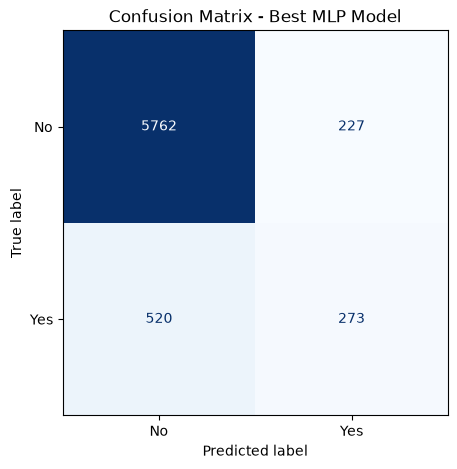

True Negatives: 5762
False Positives: 227
False Negatives: 520
True Positives: 273


In [7]:
cm = confusion_matrix(y_test, y_pred)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

fig, ax = plt.subplots(figsize=(7, 5))

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Confusion Matrix - Best MLP Model")

plt.savefig(
    output_dir / "task5_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Step 8: Identify at least 5 wrong predictions

In [8]:
from sklearn.model_selection import train_test_split

df = pd.read_csv("../Dataset/bank-full.csv", sep=";")

# Match Task 2 cleaning
df = df.drop_duplicates()
df = df.drop(columns=["duration"])

X_original = df.drop(columns=["y"])
y_original = df["y"].map({"no": 0, "yes": 1})

X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_original,
    y_original,
    test_size=0.30,
    random_state=42,
    stratify=y_original
)

X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw,
    y_temp_raw,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_raw
)

# Verify original test labels match saved test labels
assert np.array_equal(
    y_test_raw.to_numpy(), y_test
), "Test set mismatch. Check Task 2 splitting."

print("Original test records matched successfully!")

Original test records matched successfully!


In [9]:
error_df = X_test_raw.reset_index(drop=True).copy()

error_df["Actual"] = y_test
error_df["Predicted"] = y_pred
error_df["Probability_Yes"] = y_prob

error_df["Error_Type"] = np.where(
    (error_df["Actual"] == 1) &
    (error_df["Predicted"] == 0),
    "False Negative",
    np.where(
        (error_df["Actual"] == 0) &
        (error_df["Predicted"] == 1),
        "False Positive",
        "Correct"
    )
)

wrong_predictions = error_df[
    error_df["Actual"] != error_df["Predicted"]
]

print("Total wrong predictions:", len(wrong_predictions))

display(
    wrong_predictions[
        [
            "age", "job", "balance",
            "housing", "campaign",
            "Actual", "Predicted",
            "Probability_Yes", "Error_Type"
        ]
    ].head(10)
)

Total wrong predictions: 747


,age,job,balance,housing,campaign,Actual,Predicted,Probability_Yes,Error_Type
33,47,blue-collar,863,yes,2,1,0,0.046166,False Negative
38,57,management,9103,no,2,1,0,0.029540,False Negative
42,34,admin.,124,yes,4,1,0,0.026598,False Negative
44,59,admin.,2166,yes,1,1,0,0.294775,False Negative
45,80,retired,1861,no,2,0,1,0.563142,False Positive
60,38,technician,110,no,3,1,0,0.075418,False Negative
67,45,technician,1673,no,1,0,1,0.692713,False Positive
71,35,technician,354,no,3,1,0,0.080598,False Negative
72,29,blue-collar,104,yes,4,1,0,0.079236,False Negative
75,49,management,85,yes,5,1,0,0.056694,False Negative


Step 9: Select wrong predictions for report

In [10]:
false_negatives = wrong_predictions[
    wrong_predictions["Error_Type"] == "False Negative"
].head(3)

false_positives = wrong_predictions[
    wrong_predictions["Error_Type"] == "False Positive"
].head(2)

selected_errors = pd.concat([
    false_negatives,
    false_positives
])

display(
    selected_errors[
        [
            "age", "job", "balance",
            "housing", "campaign",
            "Actual", "Predicted",
            "Probability_Yes", "Error_Type"
        ]
    ]
)

selected_errors.to_csv(
    output_dir / "task5_wrong_predictions.csv",
    index=False
)

print("Selected errors:", len(selected_errors))

,age,job,balance,housing,campaign,Actual,Predicted,Probability_Yes,Error_Type
33,47,blue-collar,863,yes,2,1,0,0.046166,False Negative
38,57,management,9103,no,2,1,0,0.029540,False Negative
42,34,admin.,124,yes,4,1,0,0.026598,False Negative
45,80,retired,1861,no,2,0,1,0.563142,False Positive
67,45,technician,1673,no,1,0,1,0.692713,False Positive


Selected errors: 5


Step 10: Create simple baseline

In [11]:
majority_class = int(
    pd.Series(y_train_raw).mode().iloc[0]
)

baseline_pred = np.full(
    len(y_test),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_test, baseline_pred
)

baseline_precision = precision_score(
    y_test, baseline_pred, zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_pred, zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_pred, zero_division=0
)

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision",
        "Recall", "F1-score"
    ],
    "Majority Baseline": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ],
    "Best MLP": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(comparison_df.round(4))

,Metric,Majority Baseline,Best MLP
0,Accuracy,0.8831,0.8899
1,Precision,0.0000,0.5460
2,Recall,0.0000,0.3443
3,F1-score,0.0000,0.4223


Step 11: Check whether the model meets the targets

In [12]:
print("Project Success Criteria")
print("-" * 40)

print(
    "F1-score >= 0.40:",
    "Achieved" if test_f1 >= 0.40 else "Not Achieved"
)

print(
    "Recall >= 0.50:",
    "Achieved" if test_recall >= 0.50 else "Not Achieved"
)

print(
    "F1 better than majority baseline:",
    "Yes" if test_f1 > baseline_f1 else "No"
)

Project Success Criteria
----------------------------------------
F1-score >= 0.40: Achieved
Recall >= 0.50: Not Achieved
F1 better than majority baseline: Yes


Step 12: Save results

In [13]:
results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

results_df.to_csv(
    output_dir / "task5_test_metrics.csv",
    index=False
)

comparison_df.to_csv(
    output_dir / "task5_baseline_comparison.csv",
    index=False
)

print("Task 5 evaluation results saved successfully!")

Task 5 evaluation results saved successfully!
